# Spokane QA/QC vs. Inference

Join the DamageMap QA/QC annotation export to the model inference output and evaluate predictions against reviewer labels.

In [35]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
)

In [36]:
# change filenames here
ANNOTATION = 'annotations_revision-2730-YYYYMMDDTHHMMSS.ffffffZ.parquet'
BUILDINGS = 'spokane_with_inference.parquet'


In [37]:
data_dir = Path('.')
annotation_parq = data_dir / ANNOTATION
buildings_parq = data_dir / BUILDINGS
site = buildings_parq.stem.removesuffix('_with_inference')

out_dir = data_dir / f'{site}_output'
out_dir.mkdir(exist_ok=True)

# standardize filename
name = re.sub(r'^.*_(?=[^_]+_revision-\d+-)', '', annotation_parq.name)
name = re.sub(r'(_revision-\d+-)[a-f0-9]{64}(?=\.parquet$)', r'\1YYYYMMDDTHHMMSS.ffffffZ', name)
standardized = annotation_parq.with_name(f'{site}_{name}')
if not standardized.exists():
    annotation_parq.rename(standardized)
annotation_parq = standardized


df = pd.read_parquet(annotation_parq)

gdf = gpd.read_parquet(buildings_parq)

In [38]:
n_labels = df.groupby('_dm_feature_id')['label'].nunique()
conflict_ids = n_labels.index[n_labels > 1]
unknown_ids = df.loc[df['label'] == 'unknown', '_dm_feature_id'].unique()
review_ids = conflict_ids.union(unknown_ids)

df = df.drop_duplicates(
    subset=['_dm_feature_id', 'label'],
    keep='first',
)

## Review again

Buildings whose reviewers disagree on the label, or that any reviewer flagged as `unknown`, are written out for review and excluded from the evaluation below. `n_<label>` is the number of reviewers who chose each label.

In [39]:
reviewer_counts = (
    df[df['_dm_feature_id'].isin(review_ids)]
    .pivot_table(
        index='_dm_feature_id',
        columns='label',
        values='reviewer_id',
        aggfunc='nunique',
        fill_value=0,
    )
    .add_prefix('n_')
)

review_again = gdf.merge(
    reviewer_counts,
    left_on='id',
    right_index=True,
)

review_again.to_file(
    out_dir / f'{site}_review_again.geojson',
    driver='GeoJSON',
)

print(f'{len(review_again)} buildings to review again')
review_again[['id', 'predicted_class', 'prob_damaged', *reviewer_counts.columns]].head()

82 buildings to review again


,id,predicted_class,prob_damaged,n_damaged,n_undamaged,n_unknown
10,526a7210-652b-4a0b-a3be-7a3ffb83cf2b,damaged,0.930441,0,1,1
19,0c244e73-e80b-4da6-b0df-e1299488b86b,undamaged,0.000001,0,0,1
20,9369c5e8-430e-4446-b9e4-deb1e7efe86f,damaged,1.000000,1,0,1
21,ed94c0bc-e015-4a33-bde2-6e97bdd40566,undamaged,0.001227,0,0,1
34,192a975c-1bc2-4c8d-89b3-a22fc8e2f90d,undamaged,0.003074,0,1,1


## Evaluation

In [40]:
joined = gdf[~gdf['id'].isin(review_ids)].merge(
    df[~df['_dm_feature_id'].isin(review_ids)],
    left_on='id',
    right_on='_dm_feature_id',
    how='left',
    validate='one_to_one',
)

joined.to_parquet(out_dir / f'{site}_with_qaqc.parquet')

In [41]:
eval_df = joined.dropna(
    subset=['label', 'predicted_class']
).copy()

eval_df[['label', 'predicted_class']].value_counts()

label      predicted_class
damaged    damaged            817
undamaged  undamaged          478
           damaged             33
damaged    undamaged           17
Name: count, dtype: int64

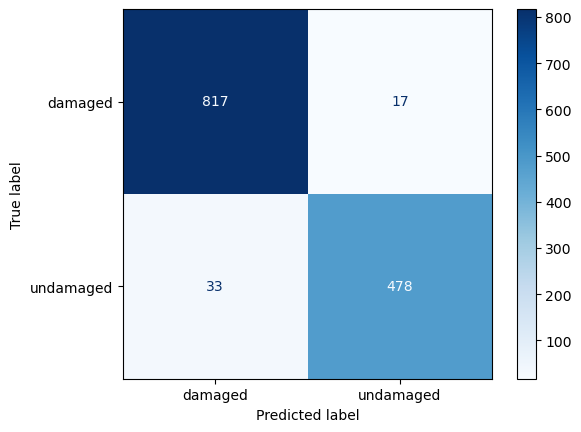

In [42]:
classes = sorted(
    set(eval_df['label']) | set(eval_df['predicted_class'])
)

cm = confusion_matrix(
    eval_df['label'],
    eval_df['predicted_class'],
    labels=classes,
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes,
).plot(cmap='Blues')

plt.show()

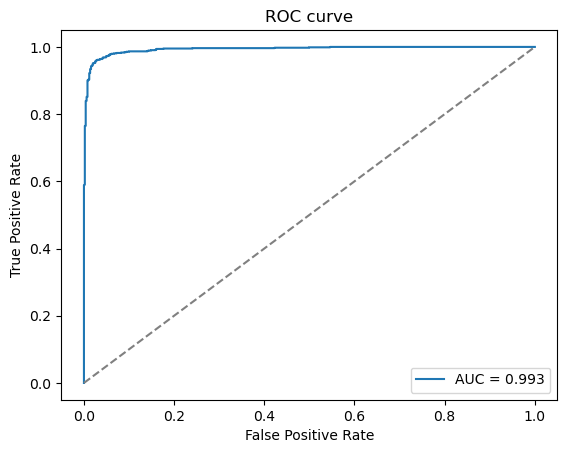

AUC: 0.9931025825132458


In [43]:
positive_label = 'damaged'

y_true = (eval_df['label'] == positive_label).astype(int)
y_pred = (eval_df['predicted_class'] == positive_label).astype(int)
y_score = eval_df['prob_damaged']

fpr, tpr, thresholds = roc_curve(y_true, y_score)
auc = roc_auc_score(y_true, y_score)

plt.plot(fpr, tpr, label=f'AUC = {auc:.3f}')
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curve')
plt.legend()
plt.show()

print('AUC:', auc)

## AUROC confidence interval

Each iteration samples a label for every review-again building from its reviewer votes (`n_damaged / (n_damaged + n_undamaged)`, or 50/50 if only `unknown` votes), adds those buildings to the evaluation set, and recomputes AUROC. `label` reflects only the uncertainty in those labels; `label + bootstrap` also resamples buildings with replacement to include sampling uncertainty.

In [44]:
rng = np.random.default_rng(0)
n_iter = 2000

review = review_again.dropna(subset=['prob_damaged'])
votes = review['n_damaged'] + review['n_undamaged']
p_damaged = (review['n_damaged'] / votes).where(votes > 0, 0.5).to_numpy()

base_true = y_true.to_numpy()
all_score = np.concatenate([y_score.to_numpy(), review['prob_damaged'].to_numpy()])

auc_label = np.empty(n_iter)
auc_full = np.empty(n_iter)
for i in range(n_iter):
    review_true = (rng.random(len(review)) < p_damaged).astype(int)
    all_true = np.concatenate([base_true, review_true])
    auc_label[i] = roc_auc_score(all_true, all_score)

    idx = rng.integers(0, len(all_true), len(all_true))
    auc_full[i] = roc_auc_score(all_true[idx], all_score[idx])

for name, aucs in [('label', auc_label), ('label + bootstrap', auc_full)]:
    lo, hi = np.percentile(aucs, [2.5, 97.5])
    print(f'{name:<18} AUC {np.median(aucs):.3f}  95% CI [{lo:.3f}, {hi:.3f}]')

label              AUC 0.982  95% CI [0.979, 0.985]
label + bootstrap  AUC 0.982  95% CI [0.975, 0.988]


In [45]:
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)

print(f'Accuracy:  {accuracy:.3f}')
print(f'Precision: {precision:.3f}')
print(f'Recall:    {recall:.3f}')

Accuracy:  0.963
Precision: 0.961
Recall:    0.980
